# تحلیل اکتشافی Superstore

این نوت‌بوک برای بررسی کیفیت داده، اعتبارسنجی پیش‌پردازش Backend و تحلیل هدفمند سودآوری است. منبع داده همان `dataset/superstore-sales.csv` است و برای بارگذاری از `backend.app.data_loader.load_dataset` استفاده می‌شود.

## خلاصه

- 1,163 ردیف، 553 سفارش یکتا و فروش کل 278,312.01 دلار وجود دارد.
- Furniture با فروش 94,647.92 دلار فقط 146.56 دلار سود دارد؛ Tables و Bookcases مجموعاً 4,718.65 دلار زیان دارند.
- باندهای تخفیف بالاتر از 40٪، 15,737.08 دلار زیان و حاشیهٔ -63.62٪ دارند. این مشاهده همبستگی است، نه اثبات علت.
- سود 2017 نسبت به 2016 به اندازهٔ 4,652.58 دلار کاهش یافت؛ Machines، East و South مهم‌ترین اجزای قابل مشاهدهٔ این تغییر هستند.


## روش و محدودیت‌ها

هر ردیف یک line item سفارش است. سود و تخفیف در این فایل مشاهده‌ای هستند؛ تحلیل، اثر علّی تخفیف یا علت عملیاتی تغییر سود را اثبات نمی‌کند. داده فقط stateهای موجود در CSV را پوشش می‌دهد و هزینه‌های خارج از ستون `Profit` را نشان نمی‌دهد.

## 1. بارگذاری داده و تنظیم نمایش

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

from backend.app.analytics import build_dashboard
from backend.app.config import get_settings
from backend.app.data_loader import load_dataset
from backend.app.schemas import DashboardFilters

pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'sales': '#2563eb', 'profit': '#0f766e', 'loss': '#c2410c', 'neutral': '#475569'}

# همان تابع Backend، داده را با اعتبارسنجی تاریخ و عدد بارگذاری می‌کند.
store = load_dataset(get_settings().dataset_path)
df = store.frame.copy()

# این سه ستون مشتق‌شده فقط برای تحلیل هستند و CSV یا DataFrame ذخیره‌شده در Backend را تغییر نمی‌دهند.
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.to_period('M')
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days

print(f'مسیر CSV: {store.source_path}')
print(f'ابعاد داده: {df.shape[0]:,} ردیف × {store.frame.shape[1]} ستون اصلی')
df.head(3)

مسیر CSV: D:\Projects\dashboard\dataset\superstore-sales.csv
ابعاد داده: 1,163 ردیف × 21 ستون اصلی


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,2016,2016-11,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,2016,2016-11,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,2016,2016-06,4


## 2. نمای کلی schema و کیفیت داده

Backend تاریخ‌ها را با فرمت صریح `YYYY-MM-DD` تبدیل می‌کند، فیلدهای عددی را اعتبارسنجی می‌کند و `Postal Code` را به‌صورت `string` نگه می‌دارد. در این بخش، نتیجهٔ همان پردازش بررسی می‌شود.

In [2]:
schema = pd.DataFrame({'column': store.frame.columns, 'dtype': store.frame.dtypes.astype(str).to_numpy(), 'null_count': store.frame.isna().sum().to_numpy()})
quality_checks = pd.Series({
    'exact_duplicate_rows': int(store.frame.duplicated().sum()),
    'repeated_order_ids': int((store.frame.groupby('Order ID').size() > 1).sum()),
    'max_line_items_in_one_order': int(store.frame.groupby('Order ID').size().max()),
    'negative_shipping_days': int((df['Shipping Days'] < 0).sum()),
    'nonpositive_quantity': int((df['Quantity'] <= 0).sum()),
    'nonpositive_sales': int((df['Sales'] <= 0).sum()),
    'discount_outside_0_to_1': int(((df['Discount'] < 0) | (df['Discount'] > 1)).sum()),
})
display(schema)
display(quality_checks.to_frame('value'))
print('Postal Code dtype:', store.frame['Postal Code'].dtype)
print('Date range:', store.min_order_date.date(), 'to', store.max_order_date.date())

,column,dtype,null_count
0,Row ID,Int64,0
1,Order ID,string,0
2,Order Date,datetime64[us],0
3,Ship Date,datetime64[us],0
4,Ship Mode,string,0
5,Customer ID,string,0
6,Customer Name,string,0
7,Segment,string,0
8,Country,string,0
9,City,string,0


,value
exact_duplicate_rows,0
repeated_order_ids,295
max_line_items_in_one_order,9
negative_shipping_days,0
nonpositive_quantity,0
nonpositive_sales,0
discount_outside_0_to_1,0


Postal Code dtype: string
Date range: 2014-01-04 to 2017-12-30


### نتیجهٔ ممیزی پیش‌پردازش

**موارد درست در Backend:** تبدیل صریح `Order Date` و `Ship Date`، اعتبارسنجی `Sales`، `Profit` و `Discount` به‌عنوان عدد، حفظ `Postal Code` به‌شکل متن، نگه‌داشتن تکرارهای `Order ID`، خطای روشن برای مقدار خالی یا نامعتبر، حفظ Profit منفی و گردکردن پس از تجمیع.

**موارد مشتق‌شدنی:** `Order Year`، `Order Month` و `Shipping Days` با تاریخ‌های معتبر و همین فرمول‌های نوت‌بوک قابل محاسبه‌اند؛ Backend آن‌ها را ذخیره نمی‌کند که برای API فعلی لازم نیست.

**نکات قابل توجه، نه خطای مشاهده‌شده:** Backend محدودهٔ تجاری `Discount` و مثبت بودن `Quantity` را جداگانه enforce نمی‌کند؛ دادهٔ فعلی در این آزمون معتبر است. همچنین آزمون‌های فعلی تغییرات فایل CSV نامعتبر را با fixture جداگانه پوشش نمی‌دهند.

## 3. آمار توصیفی و KPIهای پایه

In [3]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
profit_margin = total_profit / total_sales * 100 if total_sales else np.nan
kpis = pd.Series({
    'rows': len(df),
    'unique_orders': df['Order ID'].nunique(),
    'unique_customers': df['Customer ID'].nunique(),
    'total_sales': total_sales,
    'total_profit': total_profit,
    'profit_margin_percent': profit_margin,
    'negative_profit_line_items': int((df['Profit'] < 0).sum()),
})
display(kpis.to_frame('value'))
display(df[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days']].describe().T)

,value
rows,"1,163.00"
unique_orders,553.00
unique_customers,400.00
total_sales,"278,312.01"
total_profit,"27,147.41"
profit_margin_percent,9.75
negative_profit_line_items,213.00


,count,mean,std,min,25%,50%,75%,max
Sales,"1,163.00",239.31,587.17,1.08,17.46,55.17,209.59,"8,159.95"
Quantity,"1,163.00",3.79,2.30,1.00,2.00,3.00,5.00,14.00
Discount,"1,163.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"1,163.00",23.34,224.32,"-3,839.99",1.92,8.69,27.89,"3,177.47"
Shipping Days,"1,163.00",4.00,1.65,0.00,3.00,4.00,5.00,7.00


## 4. تحلیل زمانی فروش و سود

,Order Year,sales,profit,profit_margin
0,2014,"77,484.94","8,371.29",10.80
1,2015,"61,136.39","6,063.26",9.92
2,2016,"77,179.37","8,682.72",11.25
3,2017,"62,511.31","4,030.14",6.45


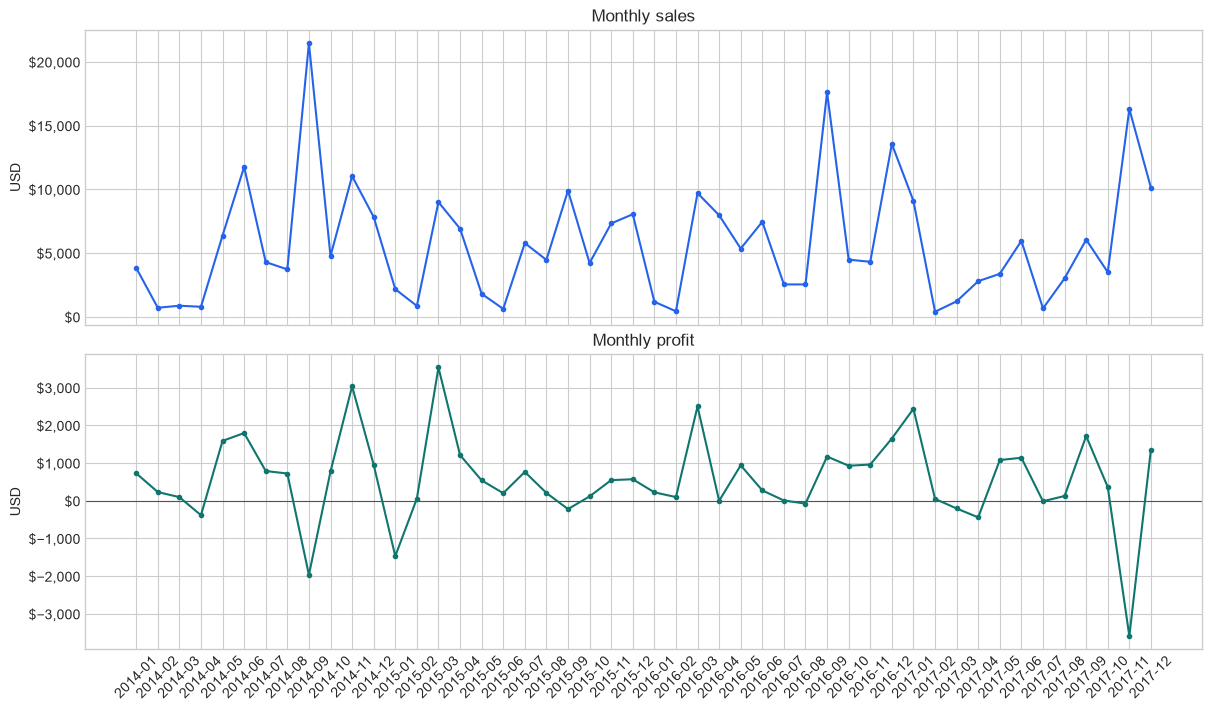

In [4]:
yearly = df.groupby('Order Year', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
yearly['profit_margin'] = yearly['profit'] / yearly['sales'] * 100
monthly = df.groupby('Order Month', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
display(yearly)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
axes[0].plot(monthly['Order Month'].astype(str), monthly['sales'], color=COLORS['sales'], marker='o', markersize=3)
axes[0].set_title('Monthly sales')
axes[0].set_ylabel('USD')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
axes[1].axhline(0, color=COLORS['neutral'], linewidth=0.8)
axes[1].plot(monthly['Order Month'].astype(str), monthly['profit'], color=COLORS['profit'], marker='o', markersize=3)
axes[1].set_title('Monthly profit')
axes[1].set_ylabel('USD')
axes[1].yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
for axis in axes:
    axis.tick_params(axis='x', rotation=45)
plt.show()

## 5. سودآوری Category و Sub-Category

محاسبهٔ حاشیه همیشه از جمع سود تقسیم بر جمع فروش انجام می‌شود، نه از میانگین حاشیهٔ line itemها.

,Category,sales,profit,profit_margin
0,Furniture,"94,647.92",146.56,0.15
1,Office Supplies,"75,069.08","13,969.17",18.61
2,Technology,"108,595.01","13,031.68",12.00


,Category,Sub-Category,sales,profit,profit_margin
3,Furniture,Tables,"32,210.85","-2,824.56",-8.77
0,Furniture,Bookcases,"14,677.18","-1,894.09",-12.91
15,Technology,Machines,"39,588.29","-1,678.77",-4.24
12,Office Supplies,Supplies,"2,393.39",-306.42,-12.80
8,Office Supplies,Fasteners,470.87,166.89,35.44
9,Office Supplies,Labels,"1,565.75",666.80,42.59
5,Office Supplies,Art,"4,319.49",876.09,20.28
4,Office Supplies,Appliances,"9,994.17","1,072.48",10.73
7,Office Supplies,Envelopes,"2,655.51","1,073.18",40.41
2,Furniture,Furnishings,"11,901.08","1,099.22",9.24


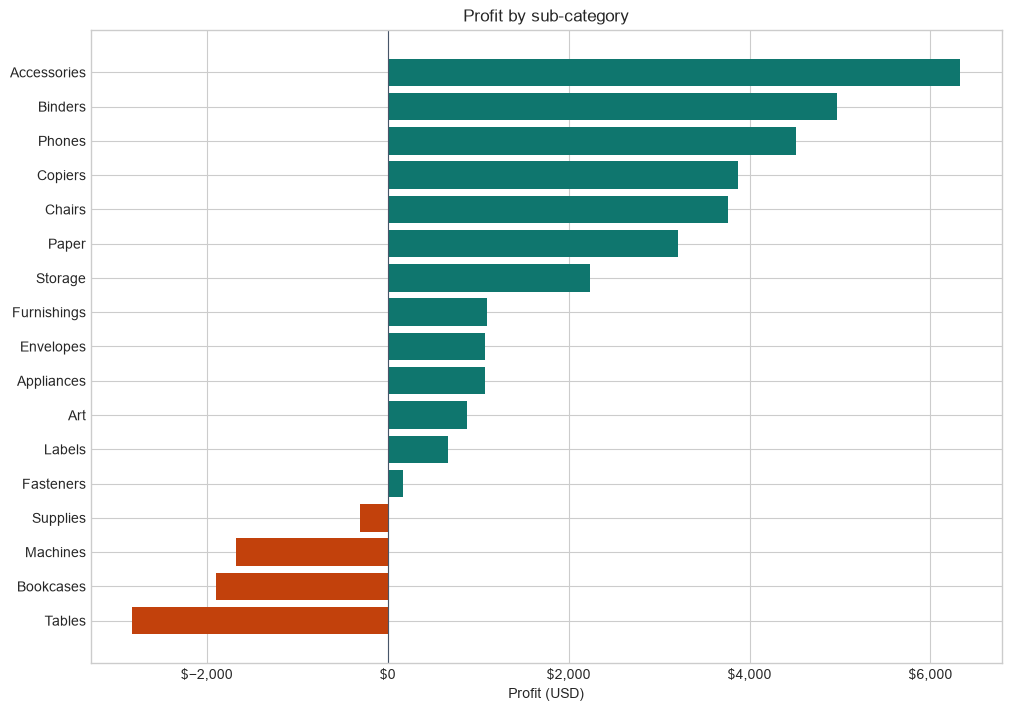

In [5]:
category = df.groupby('Category', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
category['profit_margin'] = category['profit'] / category['sales'] * 100
subcategory = df.groupby(['Category', 'Sub-Category'], as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
subcategory['profit_margin'] = subcategory['profit'] / subcategory['sales'] * 100
subcategory = subcategory.sort_values('profit')
display(category)
display(subcategory)

bar_colors = np.where(subcategory['profit'] < 0, COLORS['loss'], COLORS['profit'])
fig, ax = plt.subplots(figsize=(10, 7), layout='constrained')
ax.barh(subcategory['Sub-Category'], subcategory['profit'], color=bar_colors)
ax.axvline(0, color=COLORS['neutral'], linewidth=0.8)
ax.set_title('Profit by sub-category')
ax.set_xlabel('Profit (USD)')
ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

### پرسش A و B: چرا Furniture حاشیهٔ پایین دارد؟

Tables: 32,210.85 دلار فروش و 2,824.56- دلار سود؛ Bookcases: 14,677.18 دلار فروش و 1,894.09- دلار سود. زیان ترکیبی آن‌ها 4,718.65 دلار است. Chairs و Furnishings در مجموع این زیان را جبران می‌کنند، اما سود نهایی Furniture فقط 146.56 دلار می‌شود.

بیشترین زیان Tables و Bookcases در Pennsylvania (2,284.65- دلار)، Florida (1,057.65- دلار)، Arizona (1,018.93- دلار) و Illinois (731.53- دلار) دیده می‌شود. Segment مصرف‌کننده 3,492.23- دلار زیان دارد. در باند بالاتر از 40٪، این دو Sub-Category به‌تنهایی 4,943.68- دلار زیان دارند. این‌ها سهم‌های حسابداری هستند، نه اثبات علت قیمت‌گذاری.

In [6]:
focus = df[df['Sub-Category'].isin(['Tables', 'Bookcases'])].copy()
discount_bins = [-0.001, 0, 0.2, 0.4, 1.0]
discount_labels = ['0%', '>0% to 20%', '>20% to 40%', '>40%']
df['Discount Band'] = pd.cut(df['Discount'], bins=discount_bins, labels=discount_labels)
focus['Discount Band'] = pd.cut(focus['Discount'], bins=discount_bins, labels=discount_labels)

def summary_by(frame, columns):
    result = frame.groupby(columns, observed=False, as_index=False).agg(line_items=('Row ID', 'size'), sales=('Sales', 'sum'), profit=('Profit', 'sum'))
    result['profit_margin'] = result['profit'] / result['sales'] * 100
    return result.sort_values('profit')

display(summary_by(focus, ['State']).head(10))
display(summary_by(focus, ['Segment']))
display(summary_by(focus, ['Discount Band']))

,State,line_items,sales,profit,profit_margin
12,Pennsylvania,2,"5,148.75","-2,284.65",-44.37
4,Florida,5,"2,570.95","-1,057.65",-41.14
0,Arizona,2,"1,665.80","-1,018.93",-61.17
5,Illinois,4,"1,122.92",-731.53,-65.15
14,Texas,6,"4,231.55",-548.65,-12.97
10,New York,11,"6,549.04",-548.61,-8.38
11,Ohio,4,859.27,-384.47,-44.74
7,Massachusetts,1,"1,488.42",-297.68,-20.00
1,California,13,"10,475.72",-200.45,-1.91
2,Colorado,1,218.75,-161.88,-74.00


,Segment,line_items,sales,profit,profit_margin
0,Consumer,35,"26,988.09","-3,492.23",-12.94
2,Home Office,14,"10,442.09","-1,063.81",-10.19
1,Corporate,15,"9,457.85",-162.61,-1.72


,Discount Band,line_items,sales,profit,profit_margin
3,>40%,16,"9,236.76","-4,943.68",-53.52
2,>20% to 40%,13,"10,586.95","-2,345.84",-22.16
1,>0% to 20%,21,"14,697.35",-39.92,-0.27
0,0%,14,"12,366.97","2,610.79",21.11


## 6. تحلیل جغرافیایی

نمودار پراکندگی، فروش و سود را در یک grain ثابت، یعنی state، مقایسه می‌کند. نقطه‌های دارای سود غیرمثبت یا فروش بسیار بالا برچسب دارند.

,State,sales,profit,orders,profit_margin
36,Texas,"30,654.58","-3,783.74",47,-12.34
32,Pennsylvania,"17,726.43","-4,177.71",35,-23.57
28,North Carolina,"11,919.63","-3,485.82",18,-29.24
10,Illinois,"11,758.06","-1,271.15",32,-10.81
8,Florida,"10,619.63","-1,014.51",23,-9.55
29,Ohio,"6,781.43","-1,574.43",29,-23.22
1,Arizona,"5,953.68",-630.71,12,-10.59
16,Massachusetts,"2,359.26",-38.11,5,-1.62


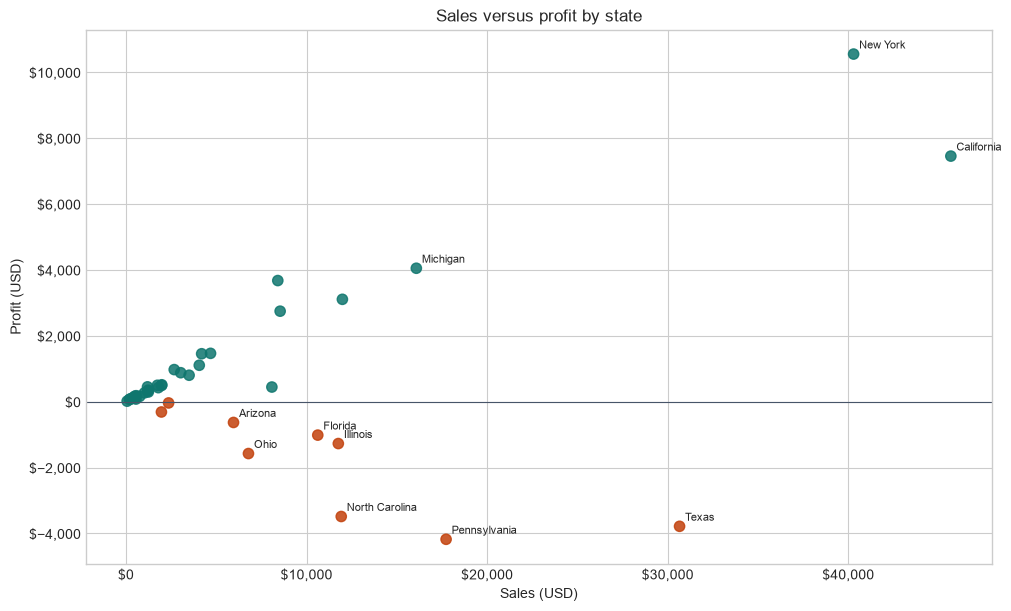

In [7]:
state = df.groupby('State', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'), orders=('Order ID', 'nunique'))
state['profit_margin'] = state['profit'] / state['sales'] * 100
high_sales_low_profit = state[(state['sales'] >= state['sales'].median()) & (state['profit'] <= 0)].sort_values('sales', ascending=False)
display(high_sales_low_profit)

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
colors = np.where(state['profit'] < 0, COLORS['loss'], COLORS['profit'])
ax.scatter(state['sales'], state['profit'], c=colors, s=55, alpha=0.85)
ax.axhline(0, color=COLORS['neutral'], linewidth=0.8)
ax.set_title('Sales versus profit by state')
ax.set_xlabel('Sales (USD)')
ax.set_ylabel('Profit (USD)')
ax.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
for row in state[(state['profit'] <= -500) | (state['sales'] >= state['sales'].nlargest(5).min())].itertuples():
    ax.annotate(row.State, (row.sales, row.profit), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.show()

### پرسش D: stateهای فروش‌بالا با سود کم یا منفی

Texas با 30,654.58 دلار فروش و 3,783.74- دلار سود، Pennsylvania با 17,726.43 دلار فروش و 4,177.71- دلار سود، و North Carolina با 11,919.63 دلار فروش و 3,485.82- دلار سود، مهم‌ترین موارد هستند. این stateها باید در رابط کاربری به‌عنوان نقاط نیازمند بررسی جزئیات تخفیف و Sub-Category قابل فیلتر باشند.

## 7. رابطهٔ تخفیف و سود

برای جلوگیری از ادعای علّی، همبستگی و تجمیع باندها فقط رابطهٔ مشاهده‌شده را نشان می‌دهند.

,Discount Band,line_items,sales,profit,profit_margin
0,0%,551,"119,315.28","36,802.92",30.85
1,>0% to 20%,447,"97,970.70","11,592.16",11.83
2,>20% to 40%,46,"36,288.10","-5,510.59",-15.19
3,>40%,119,"24,737.93","-15,737.08",-63.62


Pearson correlation, Discount vs Profit: -0.2488
Rank correlation, Discount vs Profit: -0.5186


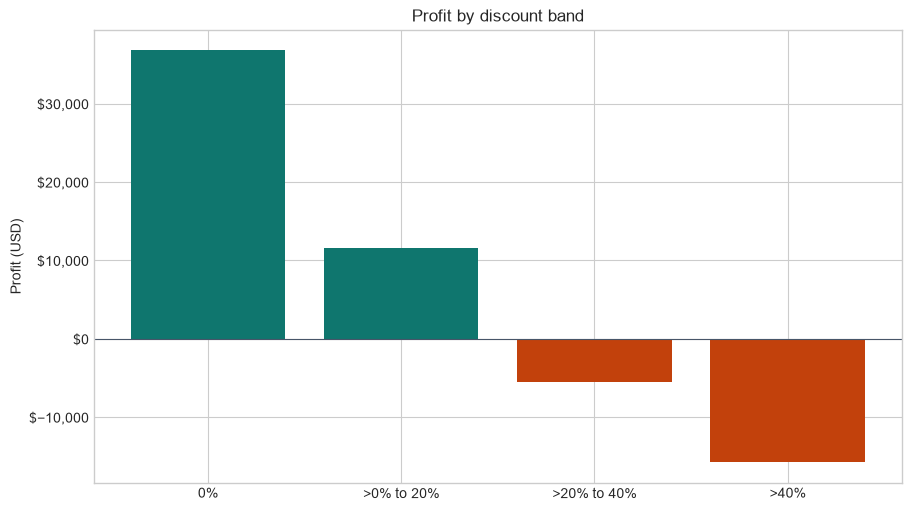

In [8]:
discount_summary = summary_by(df, ['Discount Band']).set_index('Discount Band').reindex(discount_labels).reset_index()
pearson = df['Discount'].corr(df['Profit'], method='pearson')
rank_correlation = df['Discount'].rank().corr(df['Profit'].rank(), method='pearson')
display(discount_summary)
print(f'Pearson correlation, Discount vs Profit: {pearson:.4f}')
print(f'Rank correlation, Discount vs Profit: {rank_correlation:.4f}')

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
colors = [COLORS['profit'] if value >= 0 else COLORS['loss'] for value in discount_summary['profit']]
ax.bar(discount_summary['Discount Band'].astype(str), discount_summary['profit'], color=colors)
ax.axhline(0, color=COLORS['neutral'], linewidth=0.8)
ax.set_title('Profit by discount band')
ax.set_ylabel('Profit (USD)')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

### پرسش C: آیا تخفیف بالاتر با سود پایین‌تر همراه است؟

در کل داده، همبستگی Pearson برابر 0.2488- و همبستگی رتبه‌ای برابر 0.5186- است. باند بدون تخفیف 36,802.92 دلار سود دارد، در حالی‌که باند >40٪، 15,737.08- دلار زیان دارد. این رابطه می‌تواند تحت تأثیر mix محصول، state و segment نیز باشد؛ برای نتیجهٔ علّی به آزمایش یا دادهٔ هزینه و قیمت‌گذاری نیاز است.

## 8. تحلیل Segment و تغییر سود 2016 تا 2017

,Segment,sales,profit,profit_margin
1,Corporate,"76,465.97","2,896.23",3.79
2,Home Office,"57,267.74","8,451.34",14.76
0,Consumer,"144,578.29","15,799.84",10.93


,Category,sales_2016,profit_2016,sales_2017,profit_2017,sales_delta,profit_delta
2,Technology,"25,737.68","4,900.81","28,202.63","1,848.69","2,464.95","-3,052.12"
1,Office Supplies,"23,625.68","3,904.90","15,704.61","2,572.19","-7,921.07","-1,332.71"
0,Furniture,"27,816.01",-122.98,"18,604.07",-390.74,"-9,211.94",-267.75


,Region,sales_2016,profit_2016,sales_2017,profit_2017,sales_delta,profit_delta
1,East,"29,683.49","5,023.73","14,205.39",878.30,"-15,478.10","-4,145.43"
2,South,"10,057.08",518.76,"14,744.28","-3,179.90","4,687.20","-3,698.67"
0,Central,"17,064.75","1,344.56","14,548.22","2,084.38","-2,516.53",739.82
3,West,"20,374.06","1,795.67","19,013.43","4,247.36","-1,360.63","2,451.69"


,Category,Sub-Category,sales_2016,profit_2016,sales_2017,profit_2017,sales_delta,profit_delta
15,Technology,Machines,"6,173.38","2,332.67","11,396.47","-3,115.13","5,223.09","-5,447.79"
6,Office Supplies,Binders,"8,736.73","1,037.68","1,942.73",137.46,"-6,794.00",-900.21
7,Office Supplies,Envelopes,"1,236.08",518.84,168.95,65.87,"-1,067.13",-452.97
10,Office Supplies,Paper,"2,536.68","1,090.76","1,736.76",741.32,-799.92,-349.45
3,Furniture,Tables,"8,403.77","-1,337.31","6,235.59","-1,638.60","-2,168.18",-301.29
1,Furniture,Chairs,"11,074.00","1,021.92","5,613.06",760.74,"-5,460.93",-261.19
4,Office Supplies,Appliances,"1,907.52",316.33,"3,260.90",220.30,"1,353.38",-96.02
5,Office Supplies,Art,903.86,242.76,580.84,148.77,-323.02,-93.98
0,Furniture,Bookcases,"4,900.17",32.91,"2,855.11",-23.70,"-2,045.06",-56.61
8,Office Supplies,Fasteners,161.25,58.74,140.69,52.56,-20.56,-6.18


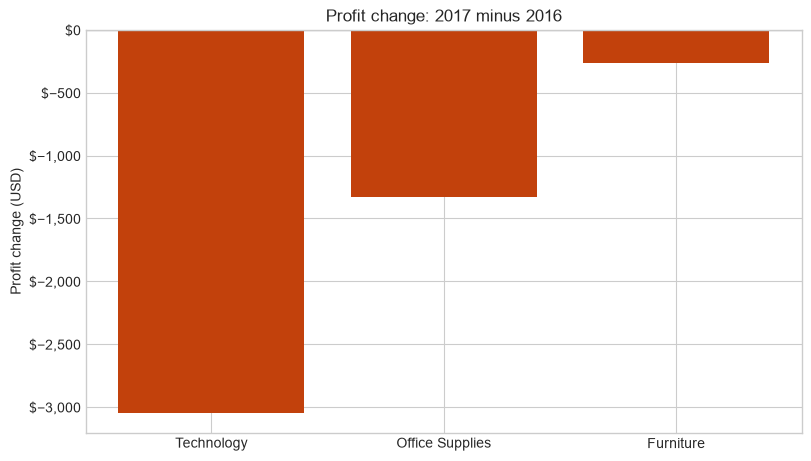

In [9]:
segment = df.groupby('Segment', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum'))
segment['profit_margin'] = segment['profit'] / segment['sales'] * 100
display(segment.sort_values('profit'))

def year_delta(group_columns):
    left = df[df['Order Year'].eq(2016)].groupby(group_columns, as_index=False).agg(sales_2016=('Sales', 'sum'), profit_2016=('Profit', 'sum'))
    right = df[df['Order Year'].eq(2017)].groupby(group_columns, as_index=False).agg(sales_2017=('Sales', 'sum'), profit_2017=('Profit', 'sum'))
    result = left.merge(right, on=group_columns, how='outer').fillna(0)
    result['sales_delta'] = result['sales_2017'] - result['sales_2016']
    result['profit_delta'] = result['profit_2017'] - result['profit_2016']
    return result.sort_values('profit_delta')

category_delta = year_delta(['Category'])
region_delta = year_delta(['Region'])
subcategory_delta = year_delta(['Category', 'Sub-Category'])
display(category_delta)
display(region_delta)
display(subcategory_delta.head(10))

fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
colors = [COLORS['profit'] if value >= 0 else COLORS['loss'] for value in category_delta['profit_delta']]
ax.bar(category_delta['Category'], category_delta['profit_delta'], color=colors)
ax.axhline(0, color=COLORS['neutral'], linewidth=0.8)
ax.set_title('Profit change: 2017 minus 2016')
ax.set_ylabel('Profit change (USD)')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

### پرسش E: افت سود 2016 تا 2017

سود از 8,682.72 دلار در 2016 به 4,030.14 دلار در 2017 رسید: 4,652.58 دلار افت (53.59٪-). فروش نیز 14,668.06 دلار کاهش یافت و حاشیه از 11.25٪ به 6.45٪ رسید.

بزرگ‌ترین جزء Sub-Category، Machines است: سود آن از 2,332.67 دلار به 3,115.13- دلار رسید؛ تغییر 5,447.79- دلار، همراه با رشد فروش 5,223.09 دلار. در Regionها، East با 4,145.43- دلار و South با 3,698.67- دلار تغییر سود منفی دارند. این تجزیه، اجزای حسابداری افت را نشان می‌دهد؛ علت عملیاتی هنوز با این CSV ثابت نمی‌شود.

## 9. نتیجه و توصیهٔ عملی

**دو insight قوی برای تکلیف:** (1) زیان Tables و Bookcases، حاشیهٔ Furniture را به 0.15٪ رسانده است؛ زیان این دو در تخفیف >40٪ به 4,943.68 دلار می‌رسد. (2) سود 2017 با وجود افزایش فروش Machines، به‌دلیل زیان Machines و افت East/South کاهش یافت.

**توصیه:** در Frontend یک هشدار یا جدول drill-down برای ترکیب `State × Sub-Category × Discount Band` قرار دهید و ابتدا تخفیف‌های بالاتر از 40٪ را برای Tables، Bookcases و Machines در Pennsylvania، Texas و North Carolina بازبینی کنید. پیش از تغییر سیاست تخفیف، قیمت تمام‌شده، قیمت فروش و علت تخصیص تخفیف را جمع‌آوری کنید.

## 10. اعتبارسنجی نهایی در برابر Backend

در این بخش، KPIهای نوت‌بوک با `build_dashboard` مقایسه می‌شوند. برای هر سال نیز همان فیلتر API و تجمیع مستقیم داده مقایسه می‌شود.

In [10]:
dashboard = build_dashboard(store, DashboardFilters())
api_kpis = dashboard['kpis']
assert len(df) == 1163
assert df['Order ID'].nunique() == 553
assert round(total_sales, 2) == 278312.01 == api_kpis['total_sales']
assert round(total_profit, 2) == 27147.41 == api_kpis['total_profit']
assert round(profit_margin, 2) == 9.75 == api_kpis['profit_margin']

api_category = pd.DataFrame(dashboard['categories']).sort_values('category').reset_index(drop=True)
eda_category = category.rename(columns={'Category': 'category'}).sort_values('category').reset_index(drop=True)
np.testing.assert_allclose(api_category['sales'], eda_category['sales'], atol=0.01)
np.testing.assert_allclose(api_category['profit'], eda_category['profit'], atol=0.01)

api_region = pd.DataFrame(dashboard['regions']).sort_values('region').reset_index(drop=True)
eda_region = df.groupby('Region', as_index=False).agg(sales=('Sales', 'sum'), profit=('Profit', 'sum')).rename(columns={'Region': 'region'}).sort_values('region').reset_index(drop=True)
np.testing.assert_allclose(api_region['sales'], eda_region['sales'], atol=0.01)
np.testing.assert_allclose(api_region['profit'], eda_region['profit'], atol=0.01)

for year in sorted(df['Order Year'].unique()):
    api_year = build_dashboard(store, DashboardFilters(years=[int(year)]))['kpis']
    direct_year = df[df['Order Year'].eq(year)]
    assert round(direct_year['Sales'].sum(), 2) == api_year['total_sales']
    assert round(direct_year['Profit'].sum(), 2) == api_year['total_profit']

print('Validation passed: baseline, category, region, and yearly totals match the backend analytics engine.')

Validation passed: baseline, category, region, and yearly totals match the backend analytics engine.
